# Aprendizagem de Máquina II — Teste 02 (RNN, LSTM e GRU)

## Setup — Bibliotecas e reprodutibilidade

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Dataset — avaliações e classes (10 min)

O conjunto público **IMDb**, disponibilizado pelo Keras, contém avaliações reais de filmes já transformadas em sequências de IDs de palavras. O problema é **classificação binária de sentimentos**:

- **0:** avaliação negativa.
- **1:** avaliação positiva.

Vamos trabalhar com **10.000 avaliações para treinamento, 2.000 para validação e 2.000 para teste**, mantendo as proporções entre as classes. Os três classificadores usarão **exatamente as mesmas partições**.

O IMDb já fornece os IDs dos tokens; portanto, nesta versão **não é necessário aprender um `TextVectorization`** com `adapt()`.

In [ ]:
# Carregamento do IMDb (download automático na primeira utilização).
V = 5000  # Mantemos os 5 mil IDs de palavras mais frequentes.
(sequencias_base_treino, rotulos_base_treino), (sequencias_base_teste, rotulos_base_teste) = (
    keras.datasets.imdb.load_data(num_words=V)
)

# Partições fixas e balanceadas. A validação vem apenas da base original de treino.
rng = np.random.default_rng(42)
indices_treino, indices_val = [], []
indices_teste = []

for classe in [0, 1]:
    ids = rng.permutation(np.flatnonzero(rotulos_base_treino == classe))
    indices_treino.extend(ids[:5000])
    indices_val.extend(ids[5000:6000])

    ids_teste = rng.permutation(np.flatnonzero(rotulos_base_teste == classe))
    indices_teste.extend(ids_teste[:1000])

indices_treino = rng.permutation(indices_treino)
indices_val = rng.permutation(indices_val)
indices_teste = rng.permutation(indices_teste)

seq_treino = [sequencias_base_treino[j] for j in indices_treino]
seq_val = [sequencias_base_treino[j] for j in indices_val]
seq_teste = [sequencias_base_teste[j] for j in indices_teste]

y_train = rotulos_base_treino[indices_treino]
y_val = rotulos_base_treino[indices_val]
y_test = rotulos_base_teste[indices_teste]

print("Treinamento:", len(seq_treino), "| Classes:", np.bincount(y_train))
print("Validação:", len(seq_val), "| Classes:", np.bincount(y_val))
print("Teste:", len(seq_teste), "| Classes:", np.bincount(y_test))
print("Exemplo de sequência (15 IDs iniciais):", seq_treino[0][:15])
print("Quantidade de tokens nesse exemplo:", len(seq_treino[0]))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Treinamento: 10000 | Classes: [5000 5000]
Validação: 2000 | Classes: [1000 1000]
Teste: 2000 | Classes: [1000 1000]
Exemplo de sequência (15 IDs iniciais): [1, 14, 9, 6, 87, 20, 13, 40, 12, 121, 2, 2, 180, 8, 79]
Quantidade de tokens nesse exemplo: 138


### Exemplos reais de avaliações — antes de iniciar as questões

Antes de treinar as redes, observe **quatro avaliações reais do IMDb**, retiradas do conjunto de treinamento: **duas negativas (0) e duas positivas (1)**. Os textos estão em inglês e foram reconstruídos a partir dos IDs dos tokens. Como o vocabulário foi limitado a 5.000 palavras, alguns termos podem aparecer como `[DESCONHECIDO]`.

Observe o conteúdo das mensagens e a relação entre o texto e o rótulo. **Esses são exemplos do tipo de dado que os três modelos aprenderão a classificar.**

In [ ]:
# Exemplos do conjunto de TREINAMENTO: duas avaliações de cada classe.
indice_palavras = keras.datasets.imdb.get_word_index()
indice_reverso = {numero + 3: palavra for palavra, numero in indice_palavras.items()}
indice_reverso.update({0: "[PAD]", 1: "[INICIO]", 2: "[DESCONHECIDO]", 3: "[RESERVADO]"})

for classe, descricao in [(0, "Negativa"), (1, "Positiva")]:
    exemplos = np.flatnonzero(y_train == classe)[:2]
    for numero, j in enumerate(exemplos, start=1):
        texto = " ".join(indice_reverso.get(int(token), "[DESCONHECIDO]")
                         for token in seq_treino[j] if token > 3)
        print(f"Classe {classe} ({descricao}) — exemplo {numero}:")
        print(texto[:600] + ("..." if len(texto) > 600 else ""))
        print()

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
Classe 0 (Negativa) — exemplo 1:
office work especially in this era of multi copy machines e mail voice mail mail and ' is territory with possibilities a previously in such films as and office space ' and very successfully this latest addition to the humor pool however ' directed by and fails to live up to it's and leaves the laughs somewhere outside the door waiting for a chance to sneak in unfortunately for the audience that chance never comes so what you get is a nice try but as the man once said no br br as the narrator star of the film playing points out in the opening in a delivered directly into the camera this story i...

Classe 0 (Negativa) — exemplo 2:
oh for crying out loud this has got to be the movie i've seen all year and i'm sorry the normally awesome john cusack was even involved in this piece of stupidity where in delivered what amounts to be the same message albeit on a more subtle somewhat more mature level delivers it

### Questões 1 e 2

**1.** Qual é a entrada do classificador e o significado dos rótulos `0` e `1`? Por que a **ordem das palavras** pode ser importante para classificar uma avaliação?

**Resposta:**  

A entrada é cada avaliação de filme transformada numa lista de números, em que cada número representa uma palavra. Todas as listas têm 120 posições. O rótulo **0** quer dizer avaliação **negativa** e o **1** quer dizer **positiva**. A ordem importa porque muda o sentido: "*good*" é positivo, mas "*not good*" é negativo. Em "*achei que seria ruim, mas foi ótimo*", o que vale é o final. Por isso usamos redes recorrentes, que leem a frase palavra por palavra e lembram do que veio antes.

**2.** Informe a quantidade de instâncias de treinamento, validação e teste e a distribuição das duas classes. Por que os três modelos devem utilizar as **mesmas partições**?

**Resposta:**

| Conjunto | Total | Negativas | Positivas |
|---|---|---|---|
| Treino | 10.000 | 5.000 | 5.000 |
| Validação | 2.000 | 1.000 | 1.000 |
| Teste | 2.000 | 1.000 | 1.000 |

Os três modelos usam os mesmos dados para que a comparação seja justa: se um modelo for melhor, é por causa da arquitetura, e não porque recebeu exemplos mais fáceis.

## 2. Sequências, timesteps e embedding (15 min)

Cada avaliação já é uma sequência de IDs de tokens. Como os comprimentos variam, precisamos definir uma quantidade fixa de passos **`T`**:

- **Padding:** completa sequências curtas com o ID `0` no final.
- **Truncamento:** mantém os `T` últimos tokens de sequências longas (`truncating="pre"`). Isso **pode eliminar informações relevantes do início** da avaliação.
- **`F`:** dimensão do vetor de embedding de cada token.
- **`H`:** quantidade de neurônios da camada recorrente.

O embedding é **aprendido durante o treinamento**; o fato de o IMDb já fornecer IDs numéricos não significa que a representação vetorial já esteja aprendida.

In [ ]:
T = 120  # Máximo de timesteps por avaliação.
F = 24   # Dimensão de embedding por token.
H = 16   # Neurônios da camada recorrente.

X_train = keras.utils.pad_sequences(seq_treino, maxlen=T, padding="post", truncating="pre")
X_val = keras.utils.pad_sequences(seq_val, maxlen=T, padding="post", truncating="pre")
X_test = keras.utils.pad_sequences(seq_teste, maxlen=T, padding="post", truncating="pre")

print("T (passos):", T, "| F (dimensão embedding):", F, "| H (neurônios):", H)
print("Vocabulário máximo (V):", V)
print("Shapes:", X_train.shape, X_val.shape, X_test.shape)
print("Tamanho original mediano:", int(np.median([len(s) for s in seq_treino])))

# Dois exemplos curtos e longos para observar padding e truncamento.
exemplo_curto = [4, 18, 52, 97]
exemplo_longo = list(range(4, T + 14))
for titulo, exemplo in [("Curto", exemplo_curto), ("Longo", exemplo_longo)]:
    convertido = keras.utils.pad_sequences([exemplo], maxlen=T, padding="post", truncating="pre")[0]
    print(f"{titulo}: comprimento original={len(exemplo)}, final={len(convertido)}")
    print("  Primeiros 8 IDs:", convertido[:8], "| Últimos 8 IDs:", convertido[-8:])

T (passos): 120 | F (dimensão embedding): 24 | H (neurônios): 16
Vocabulário máximo (V): 5000
Shapes: (10000, 120) (2000, 120) (2000, 120)
Tamanho original mediano: 176
Curto: comprimento original=4, final=120
  Primeiros 8 IDs: [ 4 18 52 97  0  0  0  0] | Últimos 8 IDs: [0 0 0 0 0 0 0 0]
Longo: comprimento original=130, final=120
  Primeiros 8 IDs: [14 15 16 17 18 19 20 21] | Últimos 8 IDs: [126 127 128 129 130 131 132 133]


In [ ]:
# O Embedding transforma os IDs em vetores de F componentes (ainda não treinados).
embedding_demo = layers.Embedding(V, F, mask_zero=True)
ids_demo = X_train[:2]
vetores_demo = embedding_demo(ids_demo)
mascara_demo = embedding_demo.compute_mask(ids_demo)

print("IDs:", ids_demo.shape)
print("Vetores do Embedding:", vetores_demo.shape)
print("Máscara (True = token válido):", mascara_demo[0].numpy()[:25])
print("Primeiro vetor:", np.round(vetores_demo[0, 0].numpy(), 3))

IDs: (2, 120)
Vetores do Embedding: (2, 120, 24)
Máscara (True = token válido): [ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True]
Primeiro vetor: [ 0.03   0.036 -0.012 -0.044  0.045  0.033  0.006 -0.031 -0.03   0.025
 -0.045 -0.014  0.039 -0.004 -0.031  0.017 -0.003  0.038 -0.003 -0.018
  0.043 -0.04  -0.034 -0.02 ]


### Questões 3 a 5

**3.** Interprete os shapes de `X_train` e `vetores_demo`. Explique as diferenças entre `T = 120`, `F = 24` e `H = 16`.

**Resposta:**  

- `X_train (10000, 120)`: 10.000 avaliações com 120 palavras cada.
- `vetores_demo (2, 120, 24)`: 2 avaliações, 120 palavras, e cada palavra virou um vetor de 24 números.

O que cada valor significa:

- **T = 120:** quantas palavras a rede lê (passos de tempo).
- **F = 24:** quantos números representam cada palavra.
- **H = 16:** quantos neurônios a camada recorrente tem, ou seja, o tamanho da "memória".

**4.** Nos dois exemplos da célula anterior, identifique onde ocorreu *padding* e onde ocorreu *truncamento*. Qual parte de uma avaliação real pode ser perdida ao utilizar `truncating="pre"`?

**Resposta:**  
- **Curto:** tinha 4 palavras e foi completado com zeros no final até chegar a 120 (**padding**).
- **Longo:** tinha 130 palavras e as 10 primeiras foram cortadas (**truncamento**).

Com `truncating="pre"`, o que se perde é o **começo** da avaliação. Como a avaliação típica tem 176 palavras, mais da metade perde o início.

**5.** O IMDb já fornece IDs de palavras e não utilizamos `TextVectorization.adapt()`. Qual é a função do `Embedding` nesse cenário? Por que **validação e teste não devem ser usados para ajustar os pesos** do embedding?

**Resposta:**  

Os IDs são só números de identificação e não dizem nada sobre o significado da palavra. O **Embedding** transforma cada ID num vetor que a rede aprende durante o treino, de modo que palavras de sentido parecido (como "*great*" e "*excellent*") ficam com vetores parecidos.

Validação e teste não podem ajustar os pesos porque servem para medir o modelo em dados que ele nunca viu. Se fossem usados no treino, o resultado ficaria artificialmente bom (vazamento de dados).

## 3. Estados produzidos pelas três arquiteturas (15 min)

As células a seguir usam **camadas ainda não treinadas** apenas para verificar as dimensões e os estados retornados. Os valores numéricos iniciais não são previsões confiáveis.

In [ ]:
# Todas as camadas recebem a mesma sequência de vetores e máscara.
rnn_demo = layers.SimpleRNN(H, return_sequences=True, return_state=True)
lstm_demo = layers.LSTM(H, return_sequences=True, return_state=True)
gru_demo = layers.GRU(H, return_sequences=True, return_state=True)

seq_rnn, h_rnn = rnn_demo(vetores_demo, mask=mascara_demo)
seq_lstm, h_lstm, c_lstm = lstm_demo(vetores_demo, mask=mascara_demo)
seq_gru, h_gru = gru_demo(vetores_demo, mask=mascara_demo)

print("SimpleRNN -> sequência:", seq_rnn.shape, "| h final:", h_rnn.shape)
print("LSTM      -> sequência:", seq_lstm.shape, "| h final:", h_lstm.shape, "| c final:", c_lstm.shape)
print("GRU       -> sequência:", seq_gru.shape, "| h final:", h_gru.shape)

SimpleRNN -> sequência: (2, 120, 16) | h final: (2, 16)
LSTM      -> sequência: (2, 120, 16) | h final: (2, 16) | c final: (2, 16)
GRU       -> sequência: (2, 120, 16) | h final: (2, 16)


### Questões 6 e 7

**6.** Por que a sequência de estados possui dimensão `(2, 120, 16)`? Explique cada dimensão. Os pesos da camada recorrente são diferentes a cada timestep?

**Resposta:**  

`(2, 120, 16)` = 2 avaliações × 120 passos × 16 valores de memória em cada passo. A saída tem os 120 passos porque usamos `return_sequences=True`.

Os pesos **não mudam** de um passo para outro: a rede usa os mesmos pesos em todas as palavras.

**7.** Quais estados são transportados entre os passos da RNN simples, da LSTM e da GRU? Diferencie a função de `hₜ` e `cₜ` na LSTM.

**Resposta:**  

- **RNN:** passa adiante só o estado `h`.
- **LSTM:** passa `h` e `c`.
- **GRU:** passa só `h`.

Na LSTM, o **`c`** é a memória de longo prazo, que guarda informação por muitos passos. O **`h`** é a memória de curto prazo, a parte da memória que a rede "mostra" em cada passo e envia adiante.

## 4. Portas e atualização da memória (20 min)

Nesta etapa, os valores são fornecidos para que você aplique manualmente as expressões vistas na aula. Use **multiplicação elemento a elemento** (`⊙`). Arredonde o resultado para três casas decimais, quando necessário.

**LSTM**

\[c_t = f_t \odot c_{t-1} + i_t \odot g_t\]

\[h_t = o_t \odot \tanh(c_t)\]

In [ ]:
# Valores conhecidos para UM passo de uma LSTM com dois neurônios.
c_anterior = np.array([0.8, -0.4])
f = np.array([0.25, 0.90])  # Forget gate
i = np.array([0.60, 0.20])  # Input gate
g = np.array([-0.50, 0.70]) # Informação candidata
o = np.array([0.80, 0.40])  # Output gate

print("c anterior:", c_anterior)
print("f:", f, "| i:", i, "| g:", g, "| o:", o)

c anterior: [ 0.8 -0.4]
f: [0.25 0.9 ] | i: [0.6 0.2] | g: [-0.5  0.7] | o: [0.8 0.4]


**GRU**

Na convenção dos slides, valores de `zₜ` próximos de 1 favorecem a preservação do estado anterior.

\[h_t = z_t \odot h_{t-1} + (1-z_t) \odot \tilde{h}_t\]

In [ ]:
# Valores conhecidos para UM passo de uma GRU com dois neurônios.
h_anterior = np.array([0.60, -0.40])
z = np.array([0.80, 0.25])          # Update gate
r = np.array([0.10, 0.90])          # Reset gate
h_candidato = np.array([-0.20, 0.50])

print("h anterior:", h_anterior)
print("z:", z, "| r:", r, "| h candidato:", h_candidato)

h anterior: [ 0.6 -0.4]
z: [0.8  0.25] | r: [0.1 0.9] | h candidato: [-0.2  0.5]


### Questões 8 a 10

**8.** Calcule manualmente o novo estado da célula `cₜ` da LSTM, mostrando a contribuição da memória preservada e da informação candidata. Utilize os dois componentes dos vetores.

**Resposta (cálculo):**  

Fórmula: **c = f × c_anterior + i × g**

| Neurônio | O que manteve (f × c_ant.) | O que entrou (i × g) | Novo c |
|---|---|---|---|
| 1 | 0,25 × 0,8 = 0,200 | 0,60 × (−0,5) = −0,300 | **−0,100** |
| 2 | 0,90 × (−0,4) = −0,360 | 0,20 × 0,7 = 0,140 | **−0,220** |

**c = [−0,100; −0,220]**

O neurônio 1 esqueceu quase tudo e aceitou a informação nova. O neurônio 2 manteve quase toda a memória antiga.

**9.** Qual é a função de cada uma das três portas da LSTM (`f`, `i`, `o`)? A informação candidata `g` é uma quarta porta? Justifique.

**Resposta:**  

- **f (esquecimento):** decide quanto da memória antiga manter.
- **i (entrada):** decide quanto da informação nova guardar.
- **o (saída):** decide quanto da memória mostrar como saída.

O **g não é uma porta**. As portas são "torneiras" com valor entre 0 e 1 que controlam o quanto passa. O `g` é o próprio conteúdo novo, com valor entre −1 e 1.

**10.** Calcule o novo estado oculto `hₜ` da GRU com os valores fornecidos. Explique a diferença entre a atuação da *update gate* (`z`) e da *reset gate* (`r`).

**Resposta (cálculo e interpretação):**  

Fórmula: **h = z × h_anterior + (1 − z) × h_candidato**

| Neurônio | Parte antiga (z × h_ant.) | Parte nova ((1 − z) × h_cand.) | Novo h |
|---|---|---|---|
| 1 | 0,80 × 0,60 = 0,480 | 0,20 × (−0,20) = −0,040 | **0,440** |
| 2 | 0,25 × (−0,40) = −0,100 | 0,75 × 0,50 = 0,375 | **0,275** |

**h = [0,440; 0,275]**

- **z (atualização):** decide no final quanto manter do estado antigo e quanto trocar pelo novo.
- **r (reset):** atua antes, decidindo quanto do passado usar para criar o candidato.

## 5. Parâmetros treináveis — RNN, LSTM e GRU (15 min)

Considere uma camada recorrente com entrada de dimensão **`F = 24`**, **`H = 16`** neurônios e **`T = 120`** timesteps.

- **RNN:** um conjunto de pesos de entrada, recorrentes e biases.
- **LSTM:** quatro conjuntos (três portas e uma informação candidata).
- **GRU:** três conjuntos (duas portas e um candidato); no Keras com `reset_after=True`, há **dois vetores de bias por conjunto**.

Compare as contagens da **camada recorrente isolada**; os modelos completos também incluem embedding e a camada de saída.

In [ ]:
# Conferir os formatos e as quantidades de parâmetros de cada camada.
camada_rnn = layers.SimpleRNN(H)
camada_lstm = layers.LSTM(H)
camada_gru = layers.GRU(H, reset_after=True)

for nome, camada in [("RNN", camada_rnn), ("LSTM", camada_lstm), ("GRU", camada_gru)]:
    camada.build((None, T, F))
    formas = [w.shape for w in camada.get_weights()]
    print(f"{nome:4s} | pesos/biases: {formas} | parâmetros: {camada.count_params()}")

RNN  | pesos/biases: [(24, 16), (16, 16), (16,)] | parâmetros: 656
LSTM | pesos/biases: [(24, 64), (16, 64), (64,)] | parâmetros: 2624
GRU  | pesos/biases: [(24, 48), (16, 48), (2, 48)] | parâmetros: 2016


### Questões 11 e 12

**11.** Calcule manualmente os parâmetros treináveis da **RNN simples** e da **LSTM**, separando pesos de entrada, pesos recorrentes e biases. Compare com o código. Se `T` passasse de 120 para 240, os totais mudariam? Por quê?

**Resposta (cálculos):**  

**RNN:** entrada 24 × 16 = 384, recorrente 16 × 16 = 256, bias 16. **Total = 656.**

**LSTM:** tem 4 blocos iguais ao da RNN (f, i, o, g): 4 × 656 = **2.624**. Isso dá 1.536 de entrada, 1.024 recorrentes e 64 de bias.

Os dois valores batem com o código. Se `T` fosse de 120 para 240, **nada mudaria**, porque os mesmos pesos são usados em todas as palavras.

**12.** Calcule manualmente os parâmetros da **GRU do Keras** (`reset_after=True`). Por que ela possui **três conjuntos** de parâmetros apesar de ter apenas duas portas? Explique a diferença no número de biases em relação à LSTM.

**Resposta (cálculo e explicação):**  

**GRU:** 3 blocos, com 3 × (384 + 256) = 1.920 pesos, mais 2 × 48 = 96 de bias. **Total = 2.016.**

São 3 blocos porque, além das duas portas (z e r), o candidato também tem seus pesos. O Keras usa **dois biases por bloco** na GRU (um para a entrada e outro para a parte recorrente), enquanto a LSTM usa um só. Mesmo assim, a GRU é menor que a LSTM.

## 6. Treinamento comparativo (25 min)

Treinaremos três classificadores com a mesma estrutura externa:

**`Embedding → camada recorrente → Dense(1, sigmoid)`**

Manteremos iguais: os dados, o vocabulário, `T`, `F`, `H`, a função de perda, o otimizador, o *learning rate*, o *batch size*, o limite máximo de épocas e a regra de parada. A **camada recorrente** (e, consequentemente, sua quantidade de parâmetros) será diferente.

Usaremos **Early Stopping**: se a *loss* de validação não melhorar por duas épocas, o treinamento é encerrado e são restaurados os pesos da melhor época. Assim, **os modelos podem executar quantidades diferentes de épocas**, mesmo utilizando a mesma regra.

**Atenção:** as métricas de treinamento, validação e teste devem ser interpretadas separadamente; não há garantia de que LSTM ou GRU tenham desempenho superior à RNN em toda execução.

In [ ]:
# Construção explícita dos três modelos.
modelo_rnn = keras.Sequential([
    keras.Input(shape=(T,), dtype="int64"),
    layers.Embedding(V, F, mask_zero=True),
    layers.SimpleRNN(H),
    layers.Dense(1, activation="sigmoid")
], name="SimpleRNN")

modelo_lstm = keras.Sequential([
    keras.Input(shape=(T,), dtype="int64"),
    layers.Embedding(V, F, mask_zero=True),
    layers.LSTM(H),
    layers.Dense(1, activation="sigmoid")
], name="LSTM")

modelo_gru = keras.Sequential([
    keras.Input(shape=(T,), dtype="int64"),
    layers.Embedding(V, F, mask_zero=True),
    layers.GRU(H, reset_after=True),
    layers.Dense(1, activation="sigmoid")
], name="GRU")

modelos = {"RNN": modelo_rnn, "LSTM": modelo_lstm, "GRU": modelo_gru}
for nome, modelo in modelos.items():
    print(f"{nome:4s} -> parâmetros totais do classificador: {modelo.count_params()}")

RNN  -> parâmetros totais do classificador: 120673
LSTM -> parâmetros totais do classificador: 122641
GRU  -> parâmetros totais do classificador: 122033


In [ ]:
# Mesma configuração de treinamento e mesma regra de parada.
EPOCAS_MAX = 8
BATCH_SIZE = 128
TAXA = 0.001
historicos = {}

for nome, modelo in modelos.items():
    keras.utils.set_random_seed(42)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TAXA),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    parada = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    )
    historico = modelo.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCAS_MAX,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=[parada],
        verbose=2
    )
    historicos[nome] = historico.history
    melhor_epoca = int(np.argmin(historico.history["val_loss"])) + 1
    print(f"{nome} | épocas executadas={len(historico.history['loss'])}",
          f"| melhor época={melhor_epoca}",
          f"| menor val_loss={min(historico.history['val_loss']):.4f}",
          f"| val_accuracy na melhor época={historico.history['val_accuracy'][melhor_epoca - 1]:.3f}")

Epoch 1/8
79/79 - 5s - 64ms/step - accuracy: 0.6933 - loss: 0.5931 - val_accuracy: 0.7825 - val_loss: 0.5011
Epoch 2/8
79/79 - 3s - 39ms/step - accuracy: 0.8423 - loss: 0.4043 - val_accuracy: 0.7870 - val_loss: 0.4578
Epoch 3/8
79/79 - 5s - 61ms/step - accuracy: 0.8747 - loss: 0.3233 - val_accuracy: 0.8175 - val_loss: 0.4206
Epoch 4/8
79/79 - 3s - 37ms/step - accuracy: 0.9063 - loss: 0.2635 - val_accuracy: 0.8185 - val_loss: 0.4335
Epoch 5/8
79/79 - 3s - 36ms/step - accuracy: 0.8945 - loss: 0.2700 - val_accuracy: 0.8140 - val_loss: 0.4243
RNN | épocas executadas=5 | melhor época=3 | menor val_loss=0.4206 | val_accuracy na melhor época=0.817
Epoch 1/8
79/79 - 8s - 97ms/step - accuracy: 0.6561 - loss: 0.6122 - val_accuracy: 0.7930 - val_loss: 0.4930
Epoch 2/8
79/79 - 6s - 74ms/step - accuracy: 0.8438 - loss: 0.3908 - val_accuracy: 0.8285 - val_loss: 0.3838
Epoch 3/8
79/79 - 5s - 59ms/step - accuracy: 0.8887 - loss: 0.2924 - val_accuracy: 0.8305 - val_loss: 0.3890
Epoch 4/8
79/79 - 5s - 6

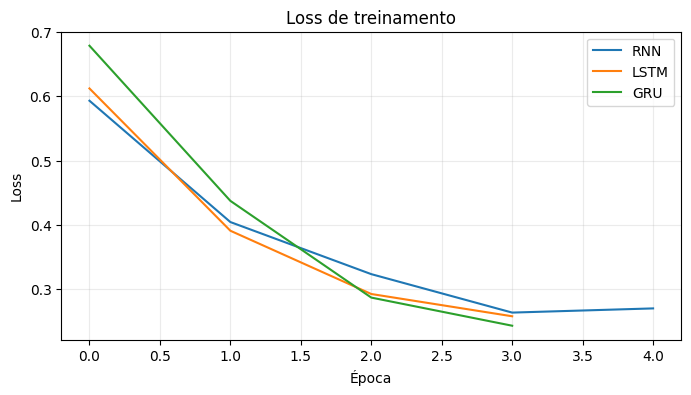

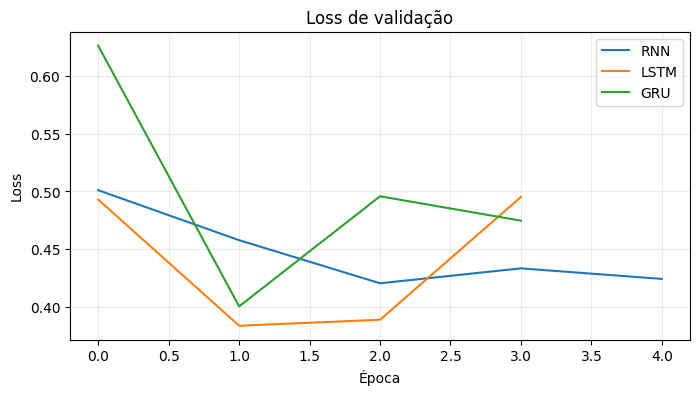

In [ ]:
# Curvas de loss de treinamento.
plt.figure(figsize=(8, 4))
for nome in modelos:
    plt.plot(historicos[nome]["loss"], label=nome)
plt.title("Loss de treinamento")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

# Curvas de loss de validação.
plt.figure(figsize=(8, 4))
for nome in modelos:
    plt.plot(historicos[nome]["val_loss"], label=nome)
plt.title("Loss de validação")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Questões 13 e 14

**13.** Identifique os hiperparâmetros de **arquitetura** e de **treinamento** usados no experimento. Quais elementos são parâmetros aprendidos? Por que a quantidade de épocas efetivamente executadas pode variar entre os modelos?

**Resposta:**  

- **Hiperparâmetros de arquitetura:** tamanho do vocabulário (5.000), T = 120, F = 24, H = 16, tipo da camada (RNN, LSTM ou GRU) e camada de saída sigmoid.
- **Hiperparâmetros de treinamento:** otimizador Adam, taxa 0,001, lote de 128, no máximo 8 épocas e Early Stopping com paciência 2.
- **Aprendido pela rede:** pesos do embedding, da camada recorrente e da camada de saída.

O número de épocas variou porque o Early Stopping para cada modelo 2 épocas depois de a validação parar de melhorar. A RNN parou na época 5, e a LSTM e a GRU na época 4.

**14.** Compare as curvas de *loss* de treinamento e validação. Qual arquitetura obteve a **menor loss de validação em sua melhor época**? Há sinais de overfitting em algum treinamento? Justifique com os gráficos e resultados.

**Resposta:**  

| Modelo | Melhor época | Menor val_loss |
|---|---|---|
| RNN | 3 | 0,4206 |
| **LSTM** | 2 | **0,3838** |
| GRU | 2 | 0,4006 |

A **LSTM** teve a menor loss de validação.

Os três modelos mostram **overfitting**: a loss de treino continua caindo, mas a de validação volta a subir depois da melhor época (na LSTM, de 0,38 para 0,50). Ou seja, a rede começa a decorar o treino. O Early Stopping resolveu isso ao recuperar os pesos da melhor época.

## 7. Avaliação em teste e interpretação de previsões (20 min)

O conjunto de **teste foi mantido fora do treinamento e do ajuste por validação**. Como suas 2.000 instâncias estão balanceadas, o desempenho esperado de um classificador que sempre prevê uma única classe é **50%**.

A saída sigmoid é a probabilidade estimada pelo modelo para a classe **positiva (1)**. Usaremos o limiar `0,5`; **confiança elevada não garante que uma previsão esteja correta**.

In [ ]:
print(f"{'Modelo':<6} {'Parâmetros':>12} {'Loss teste':>12} {'Acurácia teste':>14}")
print("-" * 52)
for nome, modelo in modelos.items():
    perda, acuracia = modelo.evaluate(X_test, y_test, verbose=0)
    print(f"{nome:<6} {modelo.count_params():>12} {perda:>12.4f} {acuracia:>14.3f}")
print("\nReferência: 0,500 de acurácia ao prever sempre uma classe no teste balanceado.")

Modelo   Parâmetros   Loss teste Acurácia teste
----------------------------------------------------
RNN          120673       0.4116          0.825
LSTM         122641       0.3880          0.835
GRU          122033       0.3767          0.834

Referência: 0,500 de acurácia ao prever sempre uma classe no teste balanceado.


In [ ]:
# Inspecionar exemplos REAIS do teste, sem utilizá-los para treinar.
# O índice invertido permite ler uma parte dos textos originalmente codificados.
indice_palavras = keras.datasets.imdb.get_word_index()
indice_reverso = {numero + 3: palavra for palavra, numero in indice_palavras.items()}
indice_reverso.update({0: "[PAD]", 1: "[INICIO]", 2: "[DESCONHECIDO]", 3: "[RESERVADO]"})

# Quatro avaliações negativas e quatro positivas, selecionadas antes de olhar as previsões.
exemplos_idx = np.concatenate([
    np.flatnonzero(y_test == 0)[:4],
    np.flatnonzero(y_test == 1)[:4]
])

probabilidades = {}
for nome, modelo in modelos.items():
    probabilidades[nome] = modelo.predict(X_test[exemplos_idx], verbose=0).ravel()

print("Probabilidades estimadas para classe 1 (positiva):")
print(f"{'Ex.':<4} {'Real':>5} {'RNN':>8} {'LSTM':>8} {'GRU':>8}")
for k, j in enumerate(exemplos_idx):
    print(f"{k+1:<4} {y_test[j]:>5} {probabilidades['RNN'][k]:>8.3f}"
          f" {probabilidades['LSTM'][k]:>8.3f} {probabilidades['GRU'][k]:>8.3f}")

print("\nTrechos das avaliações (IDs decodificados, até 250 caracteres):")
for k, j in enumerate(exemplos_idx):
    trecho = " ".join(indice_reverso.get(int(id_token), "?")
                       for id_token in X_test[j] if id_token != 0)
    print(f"{k+1}. Classe real={y_test[j]} | {trecho[:250]}...")

Probabilidades estimadas para classe 1 (positiva):
Ex.   Real      RNN     LSTM      GRU
1        0    0.079    0.082    0.107
2        0    0.211    0.260    0.132
3        0    0.550    0.580    0.342
4        0    0.067    0.086    0.037
5        1    0.882    0.868    0.892
6        1    0.909    0.892    0.899
7        1    0.174    0.750    0.643
8        1    0.773    0.834    0.848

Trechos das avaliações (IDs decodificados, até 250 caracteres):
1. Classe real=0 | movie uses flashbacks which just make the story more confusing unless viewers have some prior knowledge of the period they will quickly be lost in addition the movie was obviously filmed [DESCONHECIDO] in italian and english with various actors being...
2. Classe real=0 | a brain le looks like she is on [DESCONHECIDO] terrible acting she just ruins it henry is a little tall for his character he is also too [DESCONHECIDO] mary [DESCONHECIDO] is brilliant [DESCONHECIDO] is a little too old mrs [DESCONHECIDO] is hysteric

### Questões 15 e 16

**15.** Compare a **acurácia de teste** das três arquiteturas e a referência de `50%`. Qual apresentou melhor desempenho nesta execução? Explique por que **um único experimento** não permite concluir que essa arquitetura é universalmente superior.

**Resposta:**  

| Modelo | Acurácia no teste |
|---|---|
| RNN | 82,5% |
| LSTM | **83,5%** |
| GRU | 83,4% |

Os três ficaram bem acima dos 50% de quem "chuta" sempre a mesma classe. A LSTM foi a melhor, mas por muito pouco (0,1 ponto sobre a GRU).

Isso não prova que a LSTM é sempre melhor: foi um único teste, com uma única semente, e a diferença é de poucas avaliações. Seria preciso repetir várias vezes para ter certeza.

**16.** Escolha **duas avaliações reais** da tabela: uma com previsões semelhantes entre os modelos e outra com previsões ou probabilidades diferentes. Compare as probabilidades com o **rótulo verdadeiro**. Probabilidades altas garantem previsões corretas? Justifique com o que observou.

**Resposta:**  

- **Ex. 5 (positiva):** os três modelos deram cerca de 0,87–0,89 e todos acertaram.
- **Ex. 7 (positiva):** a RNN deu 0,174 e errou com bastante confiança (achou que era negativa). A LSTM (0,750) e a GRU (0,643) acertaram.

**Probabilidade alta não garante acerto.** A probabilidade mostra o quanto o modelo está confiante, não se ele está certo, e a RNN no Ex. 7 é a prova disso.